In [ ]:
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization,SpatialDropout1D, Activation, Add, ZeroPadding1D, MaxPooling1D, AveragePooling1D, Flatten, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras.initializers import glorot_uniform
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat, savemat
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from scipy.signal import resample
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import tensorflow as tf

In [ ]:
#Primero cargar los datos, ya han sido filtrados y segmentados
root=r'C:\Users\albai\Documents\proyecto_patrones\all_signals'
#Lista de todas las señales disponibles
all_signals=os.listdir(r'C:\Users\albai\Documents\proyecto_patrones\all_signals')
#Lista de las anotaciones disponibles
anotaciones=pd.read_csv(r"C:\Users\albai\Documents\proyecto_patrones\all_anotaciones.csv", sep=';')


label = []
pattern = []
sig = []
len_sig = []

for i in range(len(all_signals)):
    mat_data = loadmat(os.path.join(r'C:\Users\albai\Documents\proyecto_patrones\all_signals', all_signals[i]))

    # Verificar si la clave es 'ecg_signal' o 'ecg_guardar'
    if 'ecg_signal' in mat_data:
        s = mat_data['ecg_signal'][0]
    elif 'ecg_guardar' in mat_data:
        s = mat_data['ecg_guardar'][0]
    else:
        print(f"Advertencia: {all_signals[i]} no contiene 'ecg_signal' ni 'ecg_guardar'")
        continue  # Saltar este archivo si no tiene ninguna de las claves esperadas

    # Downsampling si la señal tiene 800 muestras
    if len(s)>300:
        s = resample(s, 252)

    sig.append(s)
    len_sig.append(len(s))

    aux = all_signals[i].split('_')
    if len(aux) == 6:
        label.append(aux[4])
        pattern.append(aux[5][:-4])
    else:
        label.append(aux[3])
        pattern.append(aux[4][:-4])


sig = np.array(sig, dtype=np.float32)



labels_code=[]
for i in range(0,len(label)):
    if label[i]=='V1':
        labels_code.append(0)
    if label[i]=='V2':
        labels_code.append(1)
    if label[i]=='V3':
        labels_code.append(2)
    if label[i]=='V4':
        labels_code.append(3)
    if label[i]=='V5':
        labels_code.append(4)
    if label[i]=='V6':
        labels_code.append(5)


pattern_code=[]
for i in range(0, len(pattern)):
    if pattern[i]=='1':
        pattern_code.append(1)
    if pattern[i]=='99':
        pattern_code.append(0)

pattern_code = np.array(pattern_code, dtype=np.float32)
labels_oh = to_categorical(labels_code, num_classes=6)


# Extraer identificadores de paciente de los nombres de archivo
patient_ids = [fname.split('_')[0] for fname in all_signals]

# Crear un diccionario que agrupe señales por paciente
patient_dict = {}
for i, patient in enumerate(patient_ids):
    if patient not in patient_dict:
        patient_dict[patient] = {"signals": [], "pattern_code": [], "labels_oh": []}
    patient_dict[patient]["signals"].append(sig[i])
    patient_dict[patient]["pattern_code"].append(pattern_code[i])
    patient_dict[patient]["labels_oh"].append(labels_oh[i])

# Obtener lista única de pacientes y dividirlos en train/test asegurando separación de pacientes
unique_patients = list(patient_dict.keys())
train_patients, test_patients = train_test_split(unique_patients, test_size=0.3, random_state=42)

# Asignar señales a los conjuntos de train y test
sig_train, y_train_pattern, y_train_lead = [], [], []
sig_test_val, y_test_val_pattern, y_test_val_lead = [], [], []

for patient in train_patients:
    sig_train.extend(patient_dict[patient]["signals"])
    y_train_pattern.extend(patient_dict[patient]["pattern_code"])
    y_train_lead.extend(patient_dict[patient]["labels_oh"])

for patient in test_patients:
    sig_test_val.extend(patient_dict[patient]["signals"])
    y_test_val_pattern.extend(patient_dict[patient]["pattern_code"])
    y_test_val_lead.extend(patient_dict[patient]["labels_oh"])

# Convertir a numpy arrays
sig_train = np.array(sig_train)
y_train_pattern = np.array(y_train_pattern)
y_train_lead = np.array(y_train_lead)

sig_test_val = np.array(sig_test_val)
y_test_val_pattern = np.array(y_test_val_pattern)
y_test_val_lead = np.array(y_test_val_lead)

# Dividir test en test y validación
sig_test, sig_val, y_test_pattern, y_val_pattern, y_test_lead, y_val_lead = train_test_split(
    sig_test_val, y_test_val_pattern, y_test_val_lead, test_size=0.5, random_state=42)

# Verificar tamaños de los conjuntos
len(sig_train), len(sig_test), len(sig_val)



NameError: name 'os' is not defined

In [1]:
# plt.figure(figsize=(10, 4))
# plt.plot(sig[3])
# plt.title("Señal ECG - sig[4]")
# plt.xlabel("Muestras")
# plt.ylabel("Amplitud")
# plt.grid(True)
# plt.show()

In [ ]:

#pattern_oh= to_categorical(pattern_code, num_classes=2)


In [256]:
labels_oh

array([[1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.]], dtype=float32)

In [228]:
# Extraer identificadores de paciente de los nombres de archivo
patient_ids = [fname.split('_')[0] for fname in all_signals]

# Crear un diccionario que agrupe señales por paciente
patient_dict = {}
for i, patient in enumerate(patient_ids):
    if patient not in patient_dict:
        patient_dict[patient] = {"signals": [], "pattern_code": [], "labels_oh": []}
    patient_dict[patient]["signals"].append(sig[i])
    patient_dict[patient]["pattern_code"].append(pattern_code[i])
    patient_dict[patient]["labels_oh"].append(labels_oh[i])

# Obtener lista única de pacientes y dividirlos en train/test asegurando separación de pacientes
unique_patients = list(patient_dict.keys())
train_patients, test_patients = train_test_split(unique_patients, test_size=0.3, random_state=42)

# Asignar señales a los conjuntos de train y test
sig_train, y_train_pattern, y_train_lead = [], [], []
sig_test_val, y_test_val_pattern, y_test_val_lead = [], [], []

for patient in train_patients:
    sig_train.extend(patient_dict[patient]["signals"])
    y_train_pattern.extend(patient_dict[patient]["pattern_code"])
    y_train_lead.extend(patient_dict[patient]["labels_oh"])

for patient in test_patients:
    sig_test_val.extend(patient_dict[patient]["signals"])
    y_test_val_pattern.extend(patient_dict[patient]["pattern_code"])
    y_test_val_lead.extend(patient_dict[patient]["labels_oh"])

# Convertir a numpy arrays
sig_train = np.array(sig_train)
y_train_pattern = np.array(y_train_pattern)
y_train_lead = np.array(y_train_lead)

sig_test_val = np.array(sig_test_val)
y_test_val_pattern = np.array(y_test_val_pattern)
y_test_val_lead = np.array(y_test_val_lead)

# Dividir test en test y validación
sig_test, sig_val, y_test_pattern, y_val_pattern, y_test_lead, y_val_lead = train_test_split(
    sig_test_val, y_test_val_pattern, y_test_val_lead, test_size=0.5, random_state=42)

# Verificar tamaños de los conjuntos
len(sig_train), len(sig_test), len(sig_val)


(6156, 2218, 2218)

In [ ]:
# División en Train, Test y Validation
#sig_train, sig_test_val, y_train_pattern, y_test_val_pattern, y_train_lead, y_test_val_lead = train_test_split(sig, pattern_code,labels_oh,  test_size=0.3, random_state=42)
#sig_test, sig_val, y_test_pattern, y_val_pattern, y_test_lead, y_val_lead = train_test_split(sig_test_val, y_test_val_pattern, y_test_val_lead, test_size=0.5, random_state=42)


In [ ]:
def identity_block(X, f, filters, stage, block):
    conv_name_base = f'res{stage}{block}_branch'
    bn_name_base = f'bn{stage}{block}_branch'
    
    F1, F2, F3 = filters
    X_shortcut = X
    
    X = Conv1D(F1, 1, strides=1, padding='valid', name=conv_name_base+'2a', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2a')(X)
    X=LeakyReLU(alpha=0.3)(X)
    X = SpatialDropout1D(0.3)(X)
    
    X = Conv1D(F2, f, strides=1, padding='same', name=conv_name_base+'2b', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2b')(X)
    X=LeakyReLU(alpha=0.3)(X)
    X = SpatialDropout1D(0.3)(X)
    
    X = Conv1D(F3, 1, strides=1, padding='valid', name=conv_name_base+'2c', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2c')(X)
    
    X = Add()([X, X_shortcut])
    X=LeakyReLU(alpha=0.3)(X)
    
    return X



In [ ]:
def convolutional_block(X, f, filters, stage, block, s=2):
    conv_name_base = f'res{stage}{block}_branch'
    bn_name_base = f'bn{stage}{block}_branch'
    
    F1, F2, F3 = filters
    X_shortcut = X
    
    X = Conv1D(F1, 1, strides=s, padding='valid', name=conv_name_base+'2a', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2a')(X)
    X=LeakyReLU(alpha=0.3)(X)
    X = SpatialDropout1D(0.3)(X)
    
    X = Conv1D(F2, f, strides=1, padding='same', name=conv_name_base+'2b', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2b')(X)
    X=LeakyReLU(alpha=0.3)(X)
    X = SpatialDropout1D(0.3)(X)
    
    X = Conv1D(F3, 1, strides=1, padding='valid', name=conv_name_base+'2c', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name=bn_name_base+'2c')(X)
    
    X_shortcut = Conv1D(F3, 1, strides=s, padding='valid', name=conv_name_base+'1', kernel_initializer=glorot_uniform(seed=0))(X_shortcut)
    X_shortcut = BatchNormalization(axis=2, name=bn_name_base+'1')(X_shortcut)
    
    X = Add()([X, X_shortcut])
    X=LeakyReLU(alpha=0.3)(X)
    
    return X



In [204]:
def ResNet(input_shape):
    X_input = Input(input_shape)
    X = ZeroPadding1D(3)(X_input)
    X = Conv1D(64, 7, strides=2, name='conv1', kernel_initializer=glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis=2, name='bn_conv1')(X)
    X=LeakyReLU(alpha=0.3)(X)
    X = MaxPooling1D(3, strides=2)(X)
    
    X = convolutional_block(X, 3, [128, 128, 256], 2, 'a', s=1)
    X = identity_block(X, 3, [128, 128, 256], 2, 'b')
    X = identity_block(X, 3, [128, 128, 256], 2, 'c')
    
    X = convolutional_block(X, 3, [128, 128, 512], 3, 'a', s=2)
    X = identity_block(X, 3, [128, 128, 512], 3, 'b')
    X = identity_block(X, 3, [128, 128, 512], 3, 'c')
    X = identity_block(X, 3, [128, 128, 512], 3, 'd')
    
    X = AveragePooling1D(pool_size=2, padding='same')(X)
    
    model = Model(inputs=X_input, outputs=X, name='ResNet')
    return model



In [ ]:
feature, depth = 252,1 # Ajusta estos valores según tus datos
base_model = ResNet(input_shape=(feature, depth))
headModel = Flatten()(base_model.output)
headModel = Dense(256, activation='relu', name='fc1', kernel_initializer=glorot_uniform(seed=0))(headModel)
headModel = Dense(128, activation='relu', name='fc2', kernel_initializer=glorot_uniform(seed=0))(headModel)

pattern_output = Dense(1, activation='sigmoid', name='pattern_output')(headModel)
lead_output = Dense(6, activation='softmax', name='lead_output')(headModel)

model = Model(inputs=base_model.input, outputs=[pattern_output, lead_output])

# Entrenamiento del modelo
model.compile(optimizer='adam', loss={'pattern_output': 'binary_crossentropy', 'lead_output': 'categorical_crossentropy'}, metrics=['accuracy'])
#model.fit(sig_train, [y_train_pattern, y_train_lead], validation_data=(sig_val, [y_val_pattern, y_val_lead]), epochs=100, batch_size=32)

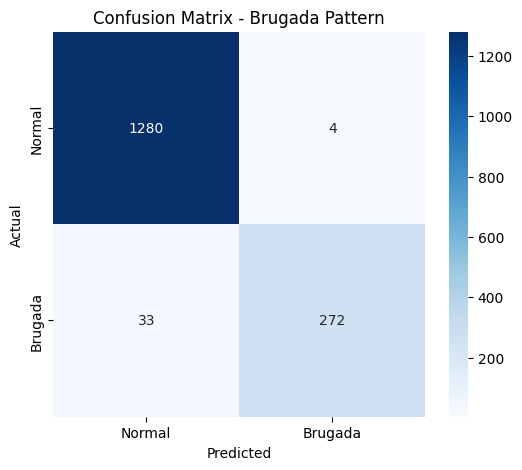

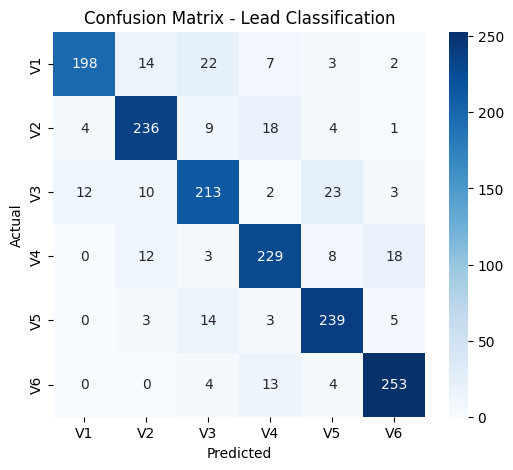

In [181]:
# Matriz de confusión para detección de patrón de Brugada
cm_pattern = confusion_matrix(y_test_pattern, y_pred_pattern)
cm_lead = confusion_matrix(y_test_lead, y_pred_lead)

# Función para graficar la matriz de confusión
def plot_confusion_matrix(cm, labels, title):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

# Graficar matriz de confusión para la detección de patrón
plot_confusion_matrix(cm_pattern, labels=["Normal", "Brugada"], title="Confusion Matrix - Brugada Pattern")

# Graficar matriz de confusión para la clasificación de la derivación
plot_confusion_matrix(cm_lead, labels=["V1", "V2", "V3", "V4", "V5", "V6"], title="Confusion Matrix - Lead Classification")


In [182]:
print("Classification Report - Brugada Pattern:")
print(classification_report(y_test_pattern, y_pred_pattern, target_names=["Normal", "Brugada"]))

print("\nClassification Report - Lead Classification:")
print(classification_report(y_test_lead, y_pred_lead, target_names=["V1", "V2", "V3", "V4", "V5", "V6"]))


Classification Report - Brugada Pattern:
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.99      1284
     Brugada       0.99      0.89      0.94       305

    accuracy                           0.98      1589
   macro avg       0.98      0.94      0.96      1589
weighted avg       0.98      0.98      0.98      1589


Classification Report - Lead Classification:
              precision    recall  f1-score   support

          V1       0.93      0.80      0.86       246
          V2       0.86      0.87      0.86       272
          V3       0.80      0.81      0.81       263
          V4       0.84      0.85      0.85       270
          V5       0.85      0.91      0.88       264
          V6       0.90      0.92      0.91       274

    accuracy                           0.86      1589
   macro avg       0.86      0.86      0.86      1589
weighted avg       0.86      0.86      0.86      1589



In [184]:
y_test_lead

array([5, 2, 4, ..., 0, 4, 3], dtype=int64)

In [212]:
# Definir número de epochs y batch sizes a probar
epochs = 100
batch_sizes = [64, 128]
results = {}

# Función para graficar la matriz de confusión
def plot_confusion_matrix(cm, labels, title, filename):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.savefig(filename)  # Guardar la imagen
    plt.close()

# Loop para entrenar con diferentes épocas y batch sizes
for batch_size in batch_sizes:
   
    print(f"Entrenando modelo con {epochs} epochs y batch size {batch_size}...")
    
    # Entrenar el modelo
    model.fit(sig_train, [y_train_pattern, y_train_lead], 
                validation_data=(sig_val, [y_val_pattern, y_val_lead]), 
                epochs=epochs, batch_size=batch_size, verbose=1)
    
    # Obtener predicciones
    y_pred_pattern = model.predict(sig_test)[0]  # Salida de detección de patrón (binaria)
    y_pred_lead = model.predict(sig_test)[1]  # Salida de clasificación de derivación (6 clases)

    # Convertir predicciones a clases
    y_pred_pattern = (y_pred_pattern > 0.5).astype(int)
    y_pred_lead = np.argmax(y_pred_lead, axis=1)

    # Convertir labels reales a formato compatible
    y_test_pattern = y_test_pattern.flatten()

    # Calcular matrices de confusión
    cm_pattern = confusion_matrix(y_test_pattern, y_pred_pattern)
    cm_lead = confusion_matrix(y_test_lead, y_pred_lead)

    # Guardar matrices de confusión
    plot_confusion_matrix(cm_pattern, ["Normal", "Brugada"], 
                            f"Confusion Matrix - Brugada Pattern ({epochs} epochs, batch {batch_size})", 
                            f"confusion_matrix_brugada_LR_{epochs}_batch{batch_size}.png")

    plot_confusion_matrix(cm_lead, ["V1", "V2", "V3", "V4", "V5", "V6"], 
                            f"Confusion Matrix - Lead Classification ({epochs} epochs, batch {batch_size})", 
                            f"confusion_matrix_lead_LR_{epochs}_batch{batch_size}.png")

    # Guardar reporte de clasificación
    report_pattern = classification_report(y_test_pattern, y_pred_pattern, target_names=["Normal", "Brugada"])
    report_lead = classification_report(y_test_lead, y_pred_lead, target_names=["V1", "V2", "V3", "V4", "V5", "V6"])

    # Guardar resultados en el diccionario
    results[(epochs, batch_size)] = {
        "confusion_matrix_pattern": cm_pattern,
        "confusion_matrix_lead": cm_lead,
        "classification_report_pattern": report_pattern,
        "classification_report_lead": report_lead
    }

    # Guardar reportes en archivos
    with open(f"classification_report_brugada_LR_{epochs}_batch{batch_size}.txt", "w") as f:
        f.write(report_pattern)
    
    with open(f"classification_report_lead_LR_{epochs}_batch{batch_size}.txt", "w") as f:
        f.write(report_lead)

    print(f"Resultados guardados para {epochs} epochs y batch size {batch_size}.\n")

Entrenando modelo con 100 epochs y batch size 64...
Epoch 1/100
116/116 [==============================] - 23s 194ms/step - loss: 7.4742e-04 - pattern_output_loss: 6.5810e-04 - lead_output_loss: 8.9320e-05 - pattern_output_accuracy: 0.9997 - lead_output_accuracy: 1.0000 - val_loss: 1.4360 - val_pattern_output_loss: 0.1737 - val_lead_output_loss: 1.2623 - val_pattern_output_accuracy: 0.9761 - val_lead_output_accuracy: 0.8571
Epoch 2/100
116/116 [==============================] - 24s 205ms/step - loss: 7.3539e-04 - pattern_output_loss: 6.4120e-04 - lead_output_loss: 9.4192e-05 - pattern_output_accuracy: 0.9996 - lead_output_accuracy: 1.0000 - val_loss: 1.4457 - val_pattern_output_loss: 0.1742 - val_lead_output_loss: 1.2715 - val_pattern_output_accuracy: 0.9761 - val_lead_output_accuracy: 0.8565
Epoch 3/100
116/116 [==============================] - 23s 199ms/step - loss: 6.2861e-04 - pattern_output_loss: 5.6139e-04 - lead_output_loss: 6.7220e-05 - pattern_output_accuracy: 0.9996 - lead_o

In [252]:
np.argmax(y_test_lead)

5

In [259]:
from sklearn.model_selection import KFold

# Definir número de epochs y batch sizes a probar
epochs_list = [50, 80, 100, 120]
batch_sizes = [32, 64, 128]
k_folds = 5  # Número de folds para validación cruzada
results = {}

# Función para graficar la matriz de confusión
def plot_confusion_matrix(cm, labels, title, filename):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.savefig(filename)  # Guardar la imagen
    plt.close()

# Configurar validación cruzada K-Fold
kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

# Loop para entrenar con diferentes épocas, batch sizes y validación cruzada
epochs = 100
batch_size = 32
fold_results = []
print(f"Entrenando modelo con {epochs} epochs, batch size {batch_size}, {k_folds}-fold cross-validation...")

for fold, (train_idx, val_idx) in enumerate(kf.split(sig_train)):
    print(f"Fold {fold+1}/{k_folds}...")
    
    # Dividir los datos en entrenamiento y validación
    X_train, X_val = sig_train[train_idx], sig_train[val_idx]
    y_train_pattern_fold, y_val_pattern_fold = y_train_pattern[train_idx], y_train_pattern[val_idx]
    y_train_lead_fold, y_val_lead_fold = y_train_lead[train_idx], y_train_lead[val_idx]
    
    # Entrenar el modelo
    model.fit(X_train, [y_train_pattern_fold, y_train_lead_fold], 
                validation_data=(X_val, [y_val_pattern_fold, y_val_lead_fold]), 
                epochs=epochs, batch_size=batch_size, verbose=1)
    
    # Obtener predicciones
    y_pred_pattern = model.predict(sig_test)[0]  # Salida de detección de patrón (binaria)
    y_pred_lead = model.predict(sig_test)[1]  # Salida de clasificación de derivación (6 clases)
    
    # Convertir predicciones a clases
    y_pred_pattern = (y_pred_pattern > 0.5).astype(int)
    y_pred_lead = np.argmax(y_pred_lead, axis=1)
    
    # Convertir labels reales a formato compatible
    y_test_pattern = y_test_pattern.flatten()
    
    # Calcular matrices de confusión
    cm_pattern = confusion_matrix(y_test_pattern, y_pred_pattern)
    cm_lead = confusion_matrix(y_test_lead, y_pred_lead)
    
    # Guardar matrices de confusión
    plot_confusion_matrix(cm_pattern, ["Normal", "Brugada"], 
                            f"Confusion Matrix - Brugada Pattern ({epochs} epochs, batch {batch_size}, fold {fold+1})", 
                            f"confusion_matrix_brugada_LR_{epochs}_batch{batch_size}_fold{fold+1}.png")
    
    plot_confusion_matrix(cm_lead, ["V1", "V2", "V3", "V4", "V5", "V6"], 
                            f"Confusion Matrix - Lead Classification ({epochs} epochs, batch {batch_size}, fold {fold+1})", 
                            f"confusion_matrix_lead_LR_{epochs}_batch{batch_size}_fold{fold+1}.png")
    
    # Guardar reporte de clasificación
    report_pattern = classification_report(y_test_pattern, y_pred_pattern, target_names=["Normal", "Brugada"])
    report_lead = classification_report(y_test_lead, y_pred_lead, target_names=["V1", "V2", "V3", "V4", "V5", "V6"])
    
    # Guardar resultados en el diccionario
    fold_results.append({
        "confusion_matrix_pattern": cm_pattern,
        "confusion_matrix_lead": cm_lead,
        "classification_report_pattern": report_pattern,
        "classification_report_lead": report_lead
    })
    
    # Guardar reportes en archivos
    with open(f"classification_report_brugada_LR_{epochs}_batch{batch_size}_fold{fold+1}.txt", "w") as f:
        f.write(report_pattern)
    
    with open(f"classification_report_lead_LR_{epochs}_batch{batch_size}_fold{fold+1}.txt", "w") as f:
        f.write(report_lead)
    
    print(f"Resultados guardados para {epochs} epochs, batch size {batch_size}, fold {fold+1}.\n")

# Guardar resultados de todos los folds
results[(epochs, batch_size)] = fold_results


Entrenando modelo con 100 epochs, batch size 32, 5-fold cross-validation...
Fold 1/5...
Epoch 1/100
154/154 [==============================] - 5s 34ms/step - loss: 0.0025 - pattern_output_loss: 9.5524e-04 - lead_output_loss: 0.0016 - pattern_output_accuracy: 0.9994 - lead_output_accuracy: 0.9996 - val_loss: 0.6012 - val_pattern_output_loss: 0.0995 - val_lead_output_loss: 0.5017 - val_pattern_output_accuracy: 0.9886 - val_lead_output_accuracy: 0.9383
Epoch 2/100
154/154 [==============================] - 5s 32ms/step - loss: 0.0013 - pattern_output_loss: 0.0012 - lead_output_loss: 1.3374e-04 - pattern_output_accuracy: 0.9992 - lead_output_accuracy: 1.0000 - val_loss: 0.6192 - val_pattern_output_loss: 0.1025 - val_lead_output_loss: 0.5167 - val_pattern_output_accuracy: 0.9903 - val_lead_output_accuracy: 0.9383
Epoch 3/100
154/154 [==============================] - 5s 32ms/step - loss: 0.0021 - pattern_output_loss: 0.0016 - lead_output_loss: 5.2047e-04 - pattern_output_accuracy: 0.9992 - 

In [ ]:
from tensorflow.keras.utils import plot_model



import graphviz

# Guardar el esquema en un archivo PNG
plot_model(model, to_file="ResNet_architecture.png", show_shapes=True, show_layer_names=True, expand_nested=True)


You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.
